# Wav to Spectrogram

Part of code is utilized from https://dev.to/dolbyio/a-beginners-guide-to-visualizing-audio-as-a-spectrogram-in-python-1mm8?comments_sort=top

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io.wavfile as wavfile
from scipy import signal
import librosa

<module 'matplotlib.pyplot' from '/opt/anaconda3/envs/chords/lib/python3.11/site-packages/matplotlib/pyplot.py'>

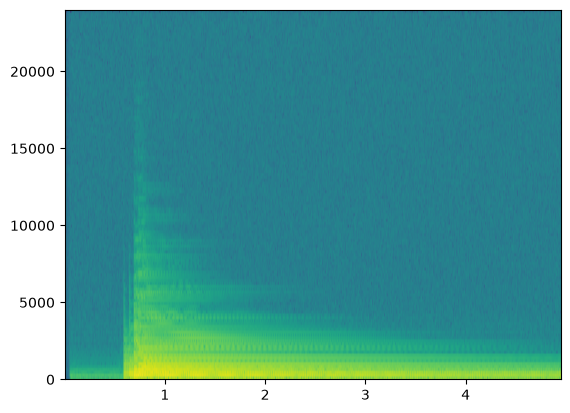

In [54]:
def change_gain(Fs, aud, db=0):
    aud = aud.astype(np.float32)
    if aud.ndim > 1:
        aud = aud.mean(axis=1)
    aud = aud / (np.max(np.abs(aud)) + 1e-9)
    aud = aud * 10 ** (db / 20)
    return np.clip(aud, -1, 1)

def change_speed(Fs, aud, rate=1.0):
    aud = aud.astype(np.float32)
    if aud.ndim > 1:
            aud = aud.mean(axis=1)
    return librosa.effects.time_stretch(aud, rate=rate)

def convert(path):
    Fs, aud = wavfile.read(path)
    aud = change_speed(Fs, aud, rate=1)
    aud = change_gain(Fs, aud, db=0)
    powerSpectrum, frequenciesFound, time, imageAxis = plt.specgram(aud, Fs=Fs)
    return plt

convert('../data/Example.wav')